In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import logsumexp
from scipy.stats import norm
from scipy.stats import gaussian_kde
import arviz as az
from bayesian_stats_course_tools.analyse import analyse_data
import dynesty

# Week 8 Exercises

# Exercise 1


**Apply LOO-CV, WAIC, DIC, and Bayes factors to the linear and quadratic models from `lectures/data/linear_fits/data_2.txt`**

Questions to answer: 
1. Which model is generally preferred using these parameters?
2. How do the LOO-CV, WAIC, and DIC results change if you change the priors on the slope and intercept, as we did for Bayes factors in Week 6?
3. How do the WAIC, LOO-CV, and DIC `elpd` values compare for the quadratic model? Are they close?

RMSE: 0.084


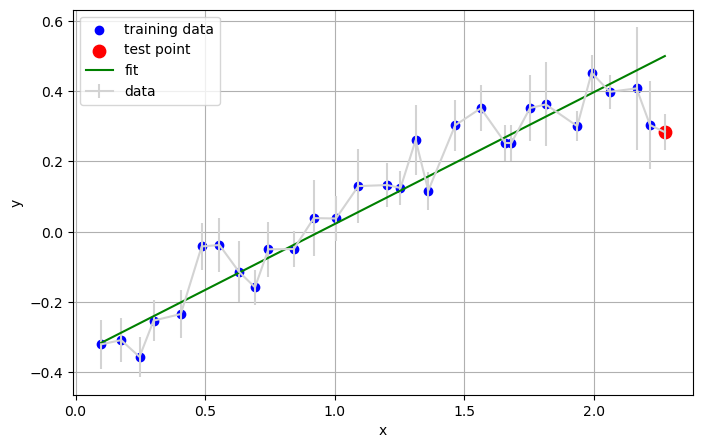

In [31]:
data = np.loadtxt("C:/Users/Sophia Kugler/Desktop/Uni/HS26/Bayesian-Stats-HS2026/lectures/data/linear_fits/data_2.txt")

x = data[:,0]
y = data[:,1]
yerr = data[:,2]

a = -0.15
v = 0.7
c = -0.45


#leave one out cross validation: small dataset 
# or when:accurate estimate of model performance is more important than computational cost
import numpy as np
from sklearn.model_selection import LeaveOneOut
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

x = data[:, 0].reshape(-1, 1)
y = data[:, 1]
yerr = data[:, 2]

cv = LeaveOneOut()

y_true, y_pred = [], []

for train_ix, test_ix in cv.split(x):

    # Split data
    x_train, x_test = x[train_ix, :], x[test_ix, :]
    y_train, y_test = y[train_ix], y[test_ix]

    # Fit model
    model = LinearRegression()
    model.fit(x_train, y_train)

    # Predict left-out point
    yhat = model.predict(x_test)

    # Store results
    y_true.append(y_test[0])
    y_pred.append(yhat[0])

# Calculate RMSE
rmse = np.sqrt(mean_squared_error(y_true, y_pred))
print(f"RMSE: {rmse:.3f}")

model.fit(
    x_train,
    y_train,
    sample_weight=1 / yerr[train_ix]**2
)


plt.figure(figsize=(8, 5))

# All data
plt.errorbar(x.ravel(), y, yerr=yerr,
             color='lightgray', label='data')

# Training data (last LOOCV iteration)
plt.scatter(x_train.ravel(), y_train,
            color='blue', label='training data')

# Test point
plt.scatter(x_test.ravel(), y_test,
            color='red', s = 80, label='test point')

# Fitted model
x_plot = np.linspace(x.min(), x.max(), 200).reshape(-1, 1)
plt.plot(x_plot.ravel(), model.predict(x_plot),
         color='green', label='fit')

plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.grid()
plt.show()


# Exercise 2

Use the data from here: https://gml.noaa.gov/webdata/ccgg/trends/co2/co2_mm_mlo.csv

In general, one can model the CO2 emission as a function of time in terms of constant, linear, quadratic, and seasonal (sinusoidal) effects that vary with periods of a year and half a year. That means we write:

$$y = \beta_0 + \beta_1 t + \beta_2 t^2 + \beta_3 \sin(2\pi t) + \beta_4 \cos(2 \pi t) + \beta_5 \sin(4 \pi t) + \beta_6 \cos(4 \pi t)$$

where $t$ is in units of years since 1990.

1. Perform least-squares linear regression to estimate the regression coefficients for the above model. Look at the residuals for the best fit model, and the uncertainty on the best fit model from the linear fit. Is there excess noise?
2. Assuming the data are drawn from a Gaussian, use `emcee` or `dynesty` to estimate the regression coefficients. If there was excess noise visible in (1), include some excess noise that is sampled (similar to our Jovian moons discussion). 
3. Plot the posterior predictive on top of the data (or show posterior predictive on residuals)
4. Use either WAIC or LOO-CV to assess whether we need the quadratic term or not.
5. For the best model, identify if there are any obvious outliers.

If you'd like, you may use [`arviz`](https://www.arviz.org/en/latest/) to perform the LOO-CV, and some of the data post processing. 